In [40]:
#importing all packages
import astropy
from astropy.io import fits
from astropy.wcs import WCS
import astropy.units as u
from astropy.stats import sigma_clipped_stats
from astropy.visualization import SqrtStretch
from astropy.visualization.mpl_normalize import ImageNormalize
import numpy as np
import matplotlib.pyplot as plt
import glob
import os
from scipy.stats import scoreatpercentile
from scipy import stats
from scipy import ndimage
from photutils.isophote import EllipseGeometry
from photutils.aperture import EllipticalAperture
from matplotlib import colors
from astropy.nddata import CCDData
from PIL import Image

In [41]:
datadir = '/Users/priyabhakta/ASTR596/Data' #data directory
os.chdir(datadir)

First, we are going to estimate the background and subtract it -- Going to use some code blocks from the surface photometry lab

In [42]:
#Dr. Rudnick's imdisplay functions:
def imdisplay(image, v1perc=10, v2perc=95, logscale=True):
    '''
    display an image 
    OPTIONAL KEYWORD PARAMETERS
    v1perc: one end of the colormap assigned to the v1perc percent lowest flux 
    v2perc: the other end of the colormap assigned to the v2perc percent highest flux    
    '''
    fig,ax = plt.subplots(figsize=(6,6))
    # make sure image is an np array
    nimage = np.array(image)
    # determine the pixel values at the 10th and 95th percentile
    v1 = scoreatpercentile(nimage,v1perc)
    v2 = scoreatpercentile(nimage,v2perc)
    # display using imshow
    #
    # you can play with alternate cmaps in the function below, such as "viridis" or "gray"
    # The 'gray_r' color map reverses the color-scale so that dark display pixels are the brightest in the image
    #
    # vmin and vmax set the min and max pixel values that
    # will be mapped to the extremes of the colormap
    print(v1,v2)
    if (logscale):
        im = ax.imshow(nimage,cmap='gray_r',aspect='equal',norm=colors.LogNorm(vmin=v1,vmax=v2),origin='lower')
    else:
        im = ax.imshow(nimage,cmap='gray_r',aspect='equal',vmin=v1,vmax=v2,origin='lower')
        
    cbar = fig.colorbar(im, ax=ax, fraction=0.04)
    cbar.ax.set_ylabel('counts')
    return fig,ax

In [43]:
def imdisplay2(image, v1perc=10, v2perc=95, logscale=True):
    '''
    display two copies of an image side-by-side
    OPTIONAL KEYWORD PARAMETERS
    v1perc: one end of the colormap assigned to the v1perc percent lowest flux 
    v2perc: the other end of the colormap assigned to the v2perc percent highest flux    
    '''
    #this makes two horizontal figures 
    fig,axs = plt.subplots(1,2,figsize=(12,6))
    # make sure image is an np array
    nimage = np.array(image)
    # determine the pixel values at the 10th and 95th percentile
    v1 = scoreatpercentile(nimage,v1perc)
    v2 = scoreatpercentile(nimage,v2perc)
    # display using imshow
    #
    # you can play with alternate cmaps in the function below, such as "viridis" or "gray"
    # The 'gray_r' color map reverses the color-scale so that dark display pixels are the brightest in the image
    #
    # vmin and vmax set the min and max pixel values that
    # will be mapped to the extremes of the colormap
    print(f"v1 = {v1:5.2f}, v2 = {v2:5.2f}")
    if (logscale):
        #plot the two figures side by side
        im0 = axs[0].imshow(nimage,cmap='gray_r',aspect='equal',norm=colors.LogNorm(vmin=v1,vmax=v2),origin='lower')
        im1 = axs[1].imshow(nimage,cmap='gray_r',aspect='equal',norm=colors.LogNorm(vmin=v1,vmax=v2),origin='lower')
    else:
        im0 = axs[0].imshow(nimage,cmap='gray_r',aspect='equal',vmin=v1,vmax=v2,origin='lower')
        im1 = axs[1].imshow(nimage,cmap='gray_r',aspect='equal',vmin=v1,vmax=v2,origin='lower')

    #plot colorbars for each subplot
    cbar0 = fig.colorbar(im0, ax=axs[0], fraction=0.04)
    cbar0.ax.set_ylabel('counts')
    cbar1 = fig.colorbar(im1, ax=axs[1], fraction=0.04)
    cbar1.ax.set_ylabel('counts')
    return fig,axs

First we're going to display the images in log scale, and then we also need to trim and rotate the images

0.08655683323740959 1.3813435316085612


Text(0.5, 1.0, 'NGC0628.phot.1.fits')

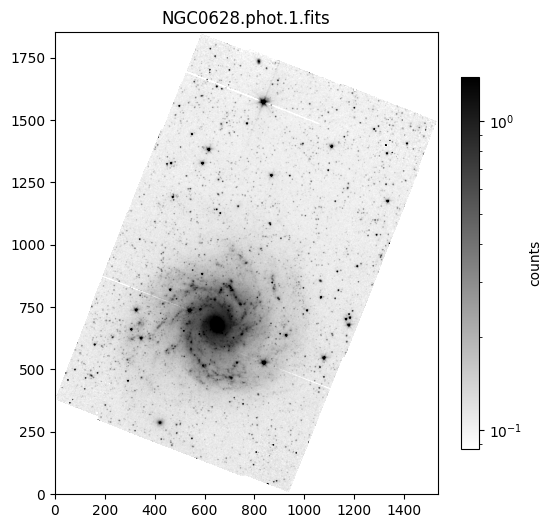

In [96]:
# Trying to load in ngc 628
imname = 'NGC0628.phot.1.fits'
data, header = fits.getdata(imname, header=True)
fig, ax = imdisplay(data,v1perc=1,v2perc=58,logscale=True)
plt.title(imname)

0.07750198394060134 0.7634567379951483


Text(0.5, 1.0, 'NGC0772.phot.1.fits')

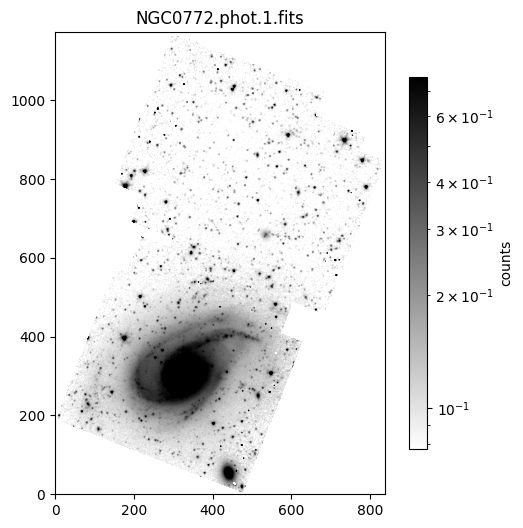

In [97]:
#loading in ngc 772
imname = 'NGC0772.phot.1.fits'
data, header = fits.getdata(imname, header=True)
fig, ax = imdisplay(data,v1perc=15,v2perc=55,logscale=True)
plt.title(imname)

0.03701480571180582 0.25213695913553236


Text(0.5, 1.0, 'NGC1232.phot.1.fits')

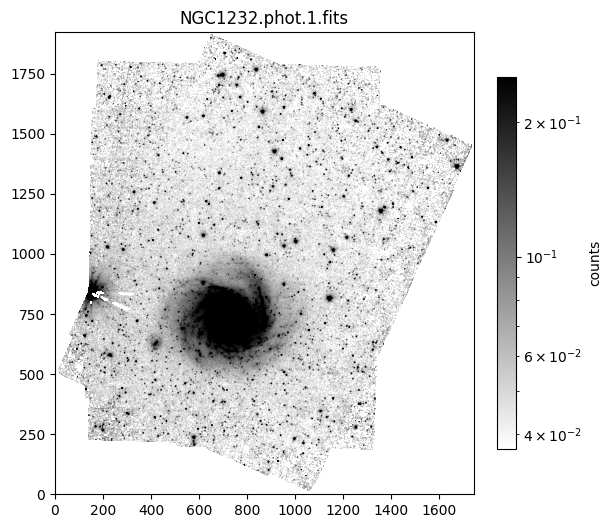

In [98]:
#ngc 1232
imname = 'NGC1232.phot.1.fits'
data, header = fits.getdata(imname, header=True)
fig, ax = imdisplay(data,v1perc=15,v2perc=65,logscale=True)
plt.title(imname)

0.03521215692162513 0.22896136045455856


Text(0.5, 1.0, 'NGC3198.phot.1.fits')

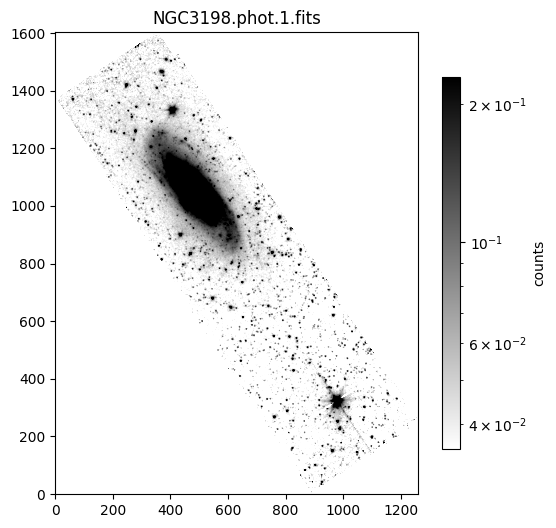

In [99]:
#ngc 3198
imname = 'NGC3198.phot.1.fits'
data, header = fits.getdata(imname, header=True)
fig, ax = imdisplay(data,v1perc=15,v2perc=35,logscale=True)
plt.title(imname)

0.012208390980958939 0.321241170167923


Text(0.5, 1.0, 'NGC5055.phot.1.fits')

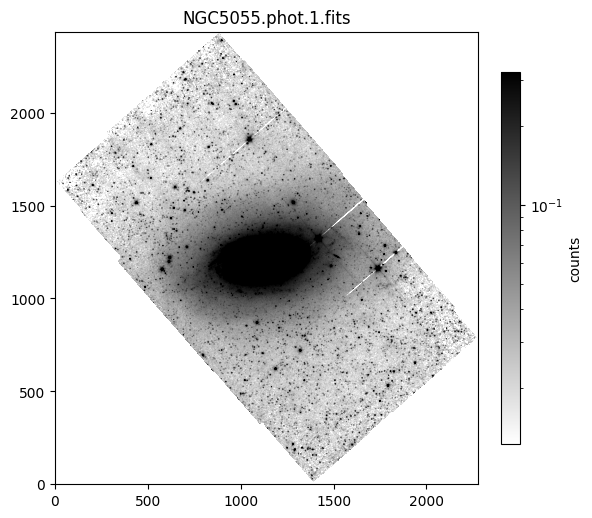

In [100]:
#ngc 5055
imname = 'NGC5055.phot.1.fits'
data, header = fits.getdata(imname, header=True)
fig, ax = imdisplay(data,v1perc=5,v2perc=45,logscale=True)
plt.title(imname)

0.003213741662912071 0.22939783334732056


Text(0.5, 1.0, 'NGC5457.phot.1.fits')

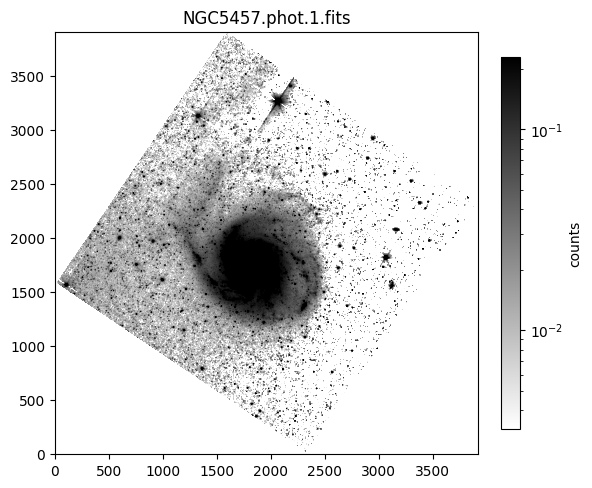

In [101]:
#ngc 5457
imname = 'NGC5457.phot.1.fits'
data, header = fits.getdata(imname, header=True)
fig, ax = imdisplay(data,v1perc=23,v2perc=50,logscale=True)
plt.title(imname)

0.028962458670139316 0.07913966961205009


Text(0.5, 1.0, 'NGC7793.phot.1.fits')

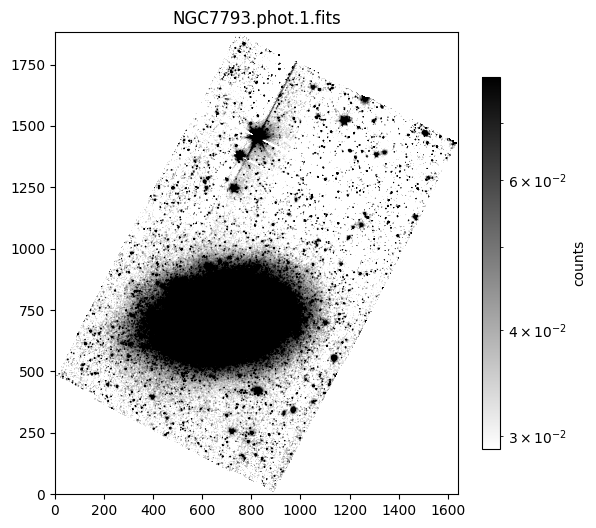

In [102]:
#ngc 7793
imname = 'NGC7793.phot.1.fits'
data, header = fits.getdata(imname, header=True)
fig, ax = imdisplay(data,v1perc=20,v2perc=45,logscale=True)
plt.title(imname)

Now to measure the background. This is another code block that was in the surface photometry lab notebook. It measures the background in two different ways.

In [92]:
def background_meas(imname,data,header,fig,ax,corners,bkg_size=5):
    #need to find ways to select regions of pixels in image
    fig,ax = imdisplay(data,v1perc=1,v2perc=35,logscale=True)

    plt.title(imname)

    #print out the x and y-dimension of the image using the header keywords
    print('image xdim = ', header['NAXIS1'], '; image ydim = ',header['NAXIS2'])
    #the length of each background box size
    #bkg_size = 200

    #make an array whose elements are the different data sections.
    reg = np.array([])


    #specify the different regions.  Each will be appended to the reg array.  the reg array is therefore 3 dimensional.  
    #the first dimension is for each region.  Each of those dimensions contains a 2D array that holds the image section.
    reg = np.append(reg, data[corners[0][0]:bkg_size-1, corners[0][1]:bkg_size-1])    #lower left corner
    reg = np.append(reg, data[corners[1][0]:bkg_size-1, corners[1][1]:])    #upper left corner
    reg = np.append(reg, data[corners[2][0]:, corners[2][1]:])    #upper right corner
    reg = np.append(reg, data[corners[3][0]:, corners[3][1]:bkg_size-1])   #lower right corner

    #print the median and mode of all the pixels. 
    bkgmode =stats.mode(reg,keepdims=False)[0]
    bkgmed = np.median(reg)
    print('mode = ',bkgmode)
    print('median = ',bkgmed)

    #Overlay rectangles with the background region indicated
    rectlist = []
    #loop through all images 
    for corn in corners:
        rect = plt.Rectangle((corn),bkg_size, bkg_size,linewidth=2,angle=0.0)
        rectlist.append(rect)
        pc = PatchCollection(rectlist,linewidth=1,edgecolor='r',facecolor='none')
        ax.add_collection(pc)
        
    return bkgmode,bkgmed

In [93]:
#initialize dictionaries that contains names of images and headers
imname = {}
data = {}
header = {}
corners = {}
bkgdim = {}

#statistics of background
bkgmode = {}
bkgmed = {}

In [94]:
#a routine to plot the images with the background measurement corners shown in red
def bkgregplot(data,header,imname, bkgdim, fig, ax):
    #define lower-left corners of each region
    corners = []
    corners.append([0,0])
    corners.append([0,header['NAXIS2']-bkgdim])
    corners.append([header['NAXIS1']-bkgdim, header['NAXIS2']-bkgdim])
    corners.append([header['NAXIS1']-bkgdim,0])

    #run the background_meas code to measure the background and plot the background regions
    bkgmode,bkgmed = background_meas(imname, data, header, fig, ax, 
                                                       corners,bkg_size=bkgdim)
    return bkgmode, bkgmed